# MiniLM: can direct weight edits repair difficult ticket routing?

A 50-example, two-class experiment on Apple Silicon. Classify the **current actionable request** as billing or account access. Archived routing metadata becomes misleading on hard examples; some requests explicitly deny or resolve the competing intent.

This notebook contains the complete experiment code and displays the locally measured results. The default opens saved results without training again. Set `RUN_EXPERIMENT = True` and **Run All** to repeat the fixed-budget MPS experiment.

**Research boundary:** this is a paper-inspired intervention study. The backbone projection follows its direction-removal formula. Semantic head replacement is a separate adaptation; the paper's Experiment 8 disallowed output-layer edits. No external editor LLM or API is called here. Extra semantic probes and repair feedback are supervision. A direct weight edit is not evidence of autonomous raw-weight understanding.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
assert (ROOT / 'experiment.py').exists(), 'Open this notebook from the project folder.'
RUN_EXPERIMENT = False


## 1. Fixed protocol and dataset

Exactly 50 total examples: **24 train + 8 ordinary test + 8 hard repair + 10 hard test**. Hard repair is development data, so success there is not generalization. The final hard test never participates in candidate construction or selection. All examples are synthetic and authored in advance; hard-test text is visible to the project author, so the holdout is procedural rather than blinded.

The training/ordinary-test metadata is always correct; the hard metadata is always reversed. This is an intentionally severe, constructed shortcut shift. It does not estimate production performance.

In [2]:
display(Markdown((ROOT / 'PROTOCOL.md').read_text()))
data = pd.read_json(ROOT / 'data/tickets.json')
display(pd.crosstab(data['split'], data['label_name']))
display(data[['id', 'split', 'text', 'label_name']])

# Protocol frozen before model execution

Task: binary routing by the customer's CURRENT actionable request: billing (0) versus account access (1). Explicitly ignore archived routing metadata, resolved issues and denied requests. 50 synthetic examples authored for this demonstration. All examples and labels are visible in the project; hard_test is held out by code and is not used for diagnosis, candidate selection or weight construction. This is procedural holdout, not a blinded independent benchmark.

Splits: train 24; ordinary test 8; hard repair/development 8; hard test 10. Every split is class-balanced. Exactly 50 total examples, not 50 training examples. Extra authored diagnostic prompts below are additional semantic supervision, not evaluation cases.

Distribution shift: archived metadata is perfectly correlated with the target during training and ordinary testing and reverses on both hard splits. Hard cases also negate or resolve a competing intent. This intentionally tests a shortcut; it is not representative production data. Hard repair/test share construction patterns, so generalization is within this synthetic shift.

Compute: all-MiniLM-L6-v2, max 96 tokens, MPS when available, one seed (42), 8 epochs, batch size 8. Freeze embeddings and first five transformer blocks; train final block and a 384-to-2 head. No early stopping, no tuning against either test set. Compare gradient repair using cached embeddings (100 tiny head-only steps) with direct edits. No API calls, no external editor LLM, no parameter sweeps over evaluation sets.

Main paper-inspired candidate family: derive an archived-metadata nuisance direction from paired diagnostic activations with the current request held fixed. Project it out of the last transformer block's attention and FFN output weights and biases at fixed strengths 0.5 and 1.0. No backward/optimizer in this stage. A zero edit is a candidate. Select by hard-repair accuracy subject to at most 1/24 drop in train accuracy; break ties by ordinary train accuracy, then fewer changed scalars. A second reasoning-directed candidate rewrites only the classification head from current-request semantic probes and removes its archived-metadata direction; same acceptance rule. Include a zero-shot semantic head control on the original pretrained encoder. Probe text and formulas must be saved before evaluation.

This is an adaptation, NOT a reproduction of the paper's Experiment 8: that experiment prohibited output-layer edits, and used a separate frontier LLM to inspect internals. Here Codex authors a fixed diagnostic/edit program, with semantic probes, and the optional head rewrite edits the output layer. No claim of autonomous LLM understanding from raw weights is tested. Candidate feedback is hard-repair supervision. Gradient-free here does not mean data-free.

Final evaluation once candidates are selected: train, ordinary test, hard repair and hard test. Report accuracy, balanced accuracy, precision/recall/F1 (macro, weighted and each class), MCC, ROC-AUC, average precision, log loss, Brier score, ECE, confusion matrices and per-example predictions. Wilson 95% accuracy intervals; exact paired McNemar test on hard-test before/after; single seed, tiny test sets, no strong statistical claims. Treat unchanged or worse performance as a valid negative result. Save all candidate scores, tensor diffs, baseline weights, runtime and hashes.

Additional fixed control declared before baseline training/final evaluation: analytic head repair with train-logit preservation and repair target margin 3, ridge 0.01; dual solve of size 32. This fits labeled repair residuals without gradients and MUST be distinguished from the paper's prohibition on fitting. It is not included in main candidate selection.


label_name,account_access,billing
split,,
hard_repair,4,4
hard_test,5,5
test,4,4
train,12,12


,id,split,text,label_name
0,train_00,train,Archived routing metadata: Billing department....,billing
1,train_01,train,Archived routing metadata: Account access depa...,account_access
2,train_02,train,Archived routing metadata: Billing department....,billing
3,train_03,train,Archived routing metadata: Account access depa...,account_access
4,train_04,train,Archived routing metadata: Billing department....,billing
5,train_05,train,Archived routing metadata: Account access depa...,account_access
6,train_06,train,Archived routing metadata: Billing department....,billing
7,train_07,train,Archived routing metadata: Account access depa...,account_access
8,train_08,train,Archived routing metadata: Billing department....,billing
9,train_09,train,Archived routing metadata: Account access depa...,account_access


## 2. Reproduce the experiment

The cells below contain the actual source. They execute only when `RUN_EXPERIMENT=True`. Frozen settings: one seed, eight epochs, batch eight, 96 tokens, first five blocks frozen, final block and classifier head trained. Apple MPS is selected automatically; CPU fallback is explicitly recorded.

The final evaluation occurs after candidate selection. Do not change the method in response to the hard-test scores and keep calling that set held out.

### Imports and fixed configuration

In [3]:
if RUN_EXPERIMENT:
    from pathlib import Path
    import os, json, time, random, copy, hashlib, platform
    ROOT=Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
    os.environ['HF_HOME']=str(ROOT/'.cache/huggingface')
    os.environ['TOKENIZERS_PARALLELISM']='false'
    os.environ.setdefault('HF_HUB_DISABLE_XET','1')
    os.environ['MPLBACKEND']='Agg'
    import numpy as np
    import pandas as pd
    import torch
    from torch import nn
    from transformers import AutoTokenizer, AutoModel
    from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
     matthews_corrcoef, roc_auc_score, average_precision_score, log_loss, confusion_matrix)
    from scipy.stats import binomtest
    import matplotlib.pyplot as plt
    import seaborn as sns
    SEED=42; EPOCHS=8; BATCH=8; MAX_LENGTH=96
    MODEL_ID='sentence-transformers/all-MiniLM-L6-v2'
    # Pin the upstream MiniLM checkpoint, independently of changing Hub main.
    REVISION='c9745ed1d9f207416be6d2e6f8de32d1f16199bf'
    DEVICE=torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if DEVICE.type=='mps': torch.mps.manual_seed(SEED)
    torch.set_num_threads(4)
    START=time.perf_counter()
    for name in ['results','checkpoints']: (ROOT/name).mkdir(exist_ok=True)
    rows=pd.read_json(ROOT/'data/tickets.json')
    assert rows.groupby('split').size().to_dict()=={'hard_repair':8,'hard_test':10,'test':8,'train':24}
    print('Device:',DEVICE,'| trainable: final transformer block + classifier head',flush=True)
    


### Model, pooling, and small-batch inference

In [4]:
if RUN_EXPERIMENT:
    TOKENIZER=AutoTokenizer.from_pretrained(MODEL_ID,revision=REVISION)
    class TicketModel(nn.Module):
     def __init__(self):
      super().__init__()
      self.encoder=AutoModel.from_pretrained(MODEL_ID,revision=REVISION,attn_implementation='eager')
      self.head=nn.Linear(384,2)
     def features(self,tokens):
      hidden=self.encoder(**tokens).last_hidden_state
      mask=tokens['attention_mask'].unsqueeze(-1)
      return nn.functional.normalize((hidden*mask).sum(1)/mask.sum(1).clamp_min(1),dim=-1)
     def forward(self,tokens): return self.head(self.features(tokens))
    def tokenize(texts):
     return {k:v.to(DEVICE) for k,v in TOKENIZER(list(texts),padding=True,truncation=True,max_length=MAX_LENGTH,return_tensors='pt').items()}
    @torch.no_grad()
    def embed(model,texts):
     model.eval()
     return torch.cat([model.features(tokenize(texts[i:i+BATCH])).cpu() for i in range(0,len(texts),BATCH)])
    @torch.no_grad()
    def predict(model,texts):
     model.eval()
     return torch.cat([model(tokenize(texts[i:i+BATCH])).softmax(-1).cpu() for i in range(0,len(texts),BATCH)]).numpy()
    def get_state(model): return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model=TicketModel().to(DEVICE)
    initial_state=get_state(model)
    train=rows[rows.split=='train'].copy(); repair=rows[rows.split=='hard_repair'].copy()
    # Authored probes encode diagnosis: archived metadata is a shortcut; route the active request.
    # They are additional weak semantic supervision and never contain hard-test strings.
    PROBES={
     'billing':['Please refund the duplicate charge.','Correct the invoice amount.','Cancel my subscription and return my payment.','Update my payment card and send a receipt.'],
     'account_access':['Please reset my password.','Unlock my account so I can sign in.','Restore my two-factor authentication.','Send me a new account recovery code.'],
     'neutral_requests':['Please help with my current request.','I need assistance with the unresolved issue.','Please handle the remaining problem.','Could you resolve my support ticket?'],
     'metadata_billing':'Archived routing metadata: Billing department. Invoice, payment, refund, subscription.',
     'metadata_access':'Archived routing metadata: Account access department. Login, password, authentication, security.'}
    (ROOT/'results/diagnostic_probes.json').write_text(json.dumps(PROBES,indent=2))
    # Semantic direction uses only authored class probes, never the final test.
    def semantic_head(model):
     centroids=torch.stack([embed(model,PROBES[c]).mean(0) for c in ['billing','account_access']])
     # Nearest-centroid linear decision rule in normalized MiniLM space.
     return 12*centroids, -6*(centroids**2).sum(1)
    zero_shot=copy.deepcopy(model)
    w,b=semantic_head(zero_shot)
    with torch.no_grad(): zero_shot.head.weight.copy_(w.to(DEVICE)); zero_shot.head.bias.copy_(b.to(DEVICE))
    


### Fixed-budget initial supervised training; no evaluation-set feedback

In [5]:
if RUN_EXPERIMENT:
    for p in model.encoder.parameters(): p.requires_grad=False
    for p in model.encoder.encoder.layer[-1].parameters(): p.requires_grad=True
    optimizer=torch.optim.AdamW([
     {'params':list(model.encoder.encoder.layer[-1].parameters()),'lr':2e-5},
     {'params':list(model.head.parameters()),'lr':3e-3}],weight_decay=.01)
    train_tokens=TOKENIZER(train.text.tolist(),padding=True,truncation=True,max_length=MAX_LENGTH,return_tensors='pt')
    y=torch.tensor(train.label.values,dtype=torch.long,device=DEVICE)
    training_log=[]
    train_started=time.perf_counter()
    for epoch in range(EPOCHS):
     model.train()
     # Frozen transformer blocks have no dropout noise; final block remains trainable.
     model.encoder.embeddings.eval()
     for layer in model.encoder.encoder.layer[:-1]: layer.eval()
     order=torch.randperm(len(train))
     losses=[]
     for ids in order.split(BATCH):
      batch={k:v[ids].to(DEVICE) for k,v in train_tokens.items()}
      optimizer.zero_grad(set_to_none=True)
      loss=nn.functional.cross_entropy(model(batch),y[ids.to(DEVICE)])
      loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
      losses.append(loss.item())
     training_log.append({'epoch':epoch+1,'loss':float(np.mean(losses))})
     print('Epoch',epoch+1,'loss',round(np.mean(losses),4),flush=True)
    train_seconds=time.perf_counter()-train_started
    model.eval(); baseline_state=get_state(model)
    torch.save(baseline_state,ROOT/'checkpoints/baseline.pt')
    TOKENIZER.save_pretrained(ROOT/'checkpoints/tokenizer')
    model.encoder.config.save_pretrained(ROOT/'checkpoints')
    pd.DataFrame(training_log).to_csv(ROOT/'results/training_log.csv',index=False)
    # Only train and repair are evaluated during diagnosis/selection.
    base_train_acc=accuracy_score(train.label,predict(model,train.text.tolist()).argmax(1))
    repair_before=predict(model,repair.text.tolist())
    repair_diagnosis=repair[['id','text','label','legacy_route']].copy()
    repair_diagnosis['baseline_prediction']=repair_before.argmax(1)
    repair_diagnosis['follows_archived_route']=repair_diagnosis.baseline_prediction==repair_diagnosis.legacy_route
    repair_diagnosis.to_csv(ROOT/'results/repair_diagnosis.csv',index=False)
    print('Baseline train accuracy:',base_train_acc,'repair accuracy:',accuracy_score(repair.label,repair_before.argmax(1)),flush=True)
    


### Reason-directed direct tensor edits, with a fixed repair-feedback budget

In [6]:
if RUN_EXPERIMENT:
    # u is an activation contrast for changing ONLY the archived route in neutral requests.
    # This probes a nuisance direction; it is not a weight-only inference claim.
    probe_a=[PROBES['metadata_billing']+' Customer current request: '+s for s in PROBES['neutral_requests']]
    probe_b=[PROBES['metadata_access']+' Customer current request: '+s for s in PROBES['neutral_requests']]
    u=(embed(model,probe_a)-embed(model,probe_b)).mean(0)
    u=nn.functional.normalize(u,dim=0)
    torch.save(u,ROOT/'checkpoints/diagnostic_direction.pt')
    head_contrast=baseline_state['head.weight'][0]-baseline_state['head.weight'][1]
    print('Classifier/nuisance cosine:',float(nn.functional.cosine_similarity(head_contrast,u,dim=0)),flush=True)
    # All candidates are prepared before either test split is evaluated.
    candidates=[]; candidate_states={}; candidate_features={}
    def consider(name,state):
     model.load_state_dict(state)
     tr=predict(model,train.text.tolist()); rp=predict(model,repair.text.tolist())
     changed=sum(int((state[k]!=baseline_state[k]).sum()) for k in state)
     row={'candidate':name,'train_accuracy':accuracy_score(train.label,tr.argmax(1)),
          'repair_accuracy':accuracy_score(repair.label,rp.argmax(1)), 'changed_scalars':changed}
     row['eligible']=row['train_accuracy']>=base_train_acc-1/24-1e-8
     candidates.append(row); candidate_states[name]=state
     print('Candidate',row,flush=True)
    consider('no_edit',baseline_state)
    edit_started=time.perf_counter()
    for strength in [.5,1.0]:
     state={k:v.clone() for k,v in baseline_state.items()}
     # Match the paper's output-direction removal form W'=W-alpha*u*(u^T W).
     for suffix in ['attention.output.dense','output.dense']:
      prefix='encoder.encoder.layer.5.'+suffix
      for ending in ['weight','bias']:
       key=prefix+'.'+ending; tensor=state[key]
       projection=u[:,None]@(u[None,:]@tensor) if tensor.ndim==2 else u*torch.dot(u,tensor)
       state[key]=tensor-strength*projection
     consider('backbone_projection_'+str(strength),state)
    # Head rewrite: preserve semantic current-request discrimination while rejecting metadata.
    # The head rewrite is explicitly outside the output-layer restrictions of paper Exp. 8.
    model.load_state_dict(baseline_state)
    w,b=semantic_head(model)
    # Remove metadata component only partially; full removal can erase real domain meaning.
    for strength in [0.,.5,1.]:
     state={k:v.clone() for k,v in baseline_state.items()}
     state['head.weight']=w-strength*(w@u)[:,None]*u[None,:]
     state['head.bias']=b.clone()
     consider('semantic_head_'+str(strength),state)
    selection=pd.DataFrame(candidates)
    # Deterministic, frozen acceptance rule: repair first, retain train, then smallest edit.
    eligible=selection[selection.eligible].sort_values(['repair_accuracy','train_accuracy','changed_scalars'],ascending=[False,False,True])
    selected=eligible.iloc[0]['candidate']
    edited_state=candidate_states[selected]
    edit_seconds=time.perf_counter()-edit_started
    selection.to_csv(ROOT/'results/edit_candidates.csv',index=False)
    # Best backbone-only edit reported separately, including a no-op if surgery fails.
    backbone_names=['no_edit','backbone_projection_0.5','backbone_projection_1.0']
    backbone_choice=eligible[eligible.candidate.isin(backbone_names)].iloc[0]['candidate']
    print('Selected:',selected,'| backbone-only:',backbone_choice,flush=True)
    torch.save({k:v for k,v in candidate_states[backbone_choice].items() if not torch.equal(v,baseline_state[k])},ROOT/'checkpoints/backbone_edited_tensors.pt')
    patch={k:edited_state[k]-baseline_state[k] for k in baseline_state if not torch.equal(edited_state[k],baseline_state[k])}
    torch.save({'candidate':selected,'delta':patch},ROOT/'checkpoints/weight_patch.pt')
    torch.save({k:edited_state[k] for k in patch},ROOT/'checkpoints/edited_tensors.pt')
    # Save exact replacement tensors as well as deltas to avoid floating-point roundtrip drift.
    changed_details=[]
    for k in patch:
     delta=patch[k]
     changed_details.append({'tensor':k,'changed_scalars':int(torch.count_nonzero(delta)),
      'frobenius_delta':float(delta.norm()),'frobenius_before':float(baseline_state[k].norm()),
      'matrix_rank_delta':int(torch.linalg.matrix_rank(delta)) if delta.ndim==2 else None})
    pd.DataFrame(changed_details,columns=['tensor','changed_scalars','frobenius_delta','frobenius_before','matrix_rank_delta']).to_csv(ROOT/'results/weight_changes.csv',index=False)
    


### Compute-light gradient repair control on the identical 8 repair examples

In [7]:
if RUN_EXPERIMENT:
    # Cache final representations, then train ONLY the 770-parameter head on train + repair.
    model.load_state_dict(baseline_state)
    replay=pd.concat([train,repair])
    X=embed(model,replay.text.tolist()).to(DEVICE)
    y_replay=torch.tensor(replay.label.values,dtype=torch.long,device=DEVICE)
    head=copy.deepcopy(model.head)
    head_optimizer=torch.optim.AdamW(head.parameters(),lr=.03,weight_decay=.01)
    control_started=time.perf_counter()
    for step in range(100):
     head_optimizer.zero_grad(set_to_none=True)
     loss=nn.functional.cross_entropy(head(X),y_replay)
     loss.backward(); head_optimizer.step()
    control_seconds=time.perf_counter()-control_started
    gradient_state={k:v.clone() for k,v in baseline_state.items()}
    gradient_state['head.weight']=head.weight.detach().cpu().clone()
    gradient_state['head.bias']=head.bias.detach().cpu().clone()
    torch.save({'head.weight':gradient_state['head.weight'],'head.bias':gradient_state['head.bias']},ROOT/'checkpoints/gradient_control_head.pt')
    
    # Analytic supervised repair control: fixed ridge residual solve, not paper-style no-fitting.
    # Preserve original train logits while assigning margin 3 to the eight repair labels.
    # Use only train+repair; solve a 32-by-32 dual system, with a bias coordinate.
    analytic_started=time.perf_counter()
    X_cpu=X.detach().cpu()
    Z=torch.cat([X_cpu,torch.ones(len(X_cpu),1)],dim=1)
    old_head=torch.cat([baseline_state['head.weight'],baseline_state['head.bias'][:,None]],dim=1)
    target=Z@old_head.T
    repair_targets=torch.nn.functional.one_hot(y_replay.detach().cpu()[-len(repair):],2).float()*3.-1.5
    target[-len(repair):]=repair_targets
    residual=target-Z@old_head.T
    ridge=0.01
    new_head=old_head+(Z.T@torch.linalg.solve(Z@Z.T+ridge*torch.eye(len(Z)),residual)).T
    analytic_state={k:v.clone() for k,v in baseline_state.items()}
    analytic_state['head.weight']=new_head[:,:-1].clone()
    analytic_state['head.bias']=new_head[:,-1].clone()
    analytic_seconds=time.perf_counter()-analytic_started
    torch.save({'head.weight':analytic_state['head.weight'],'head.bias':analytic_state['head.bias']},ROOT/'checkpoints/analytic_control_head.pt')
    torch.save({'candidate':'analytic_head_repair','delta':{k:analytic_state[k]-baseline_state[k] for k in ['head.weight','head.bias']}},ROOT/'checkpoints/analytic_weight_patch.pt')
    
    


### Final evaluation: the first use of ordinary and hard-test examples in model code

In [8]:
if RUN_EXPERIMENT:
    # No further edits or hyperparameter choices are allowed below this point.
    def wilson(correct,n):
     z=1.959963984540054; p=correct/n; den=1+z*z/n
     center=(p+z*z/(2*n))/den
     half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
     return center-half,center+half
    def metrics(y,probs):
     pred=probs.argmax(1); n=len(y)
     lo,hi=wilson(int((pred==y).sum()),n)
     out={'n':n,'correct':int((pred==y).sum()),'accuracy':accuracy_score(y,pred),
     'accuracy_ci95_low':lo,'accuracy_ci95_high':hi,'balanced_accuracy':balanced_accuracy_score(y,pred),
     'mcc':matthews_corrcoef(y,pred),'roc_auc':roc_auc_score(y,probs[:,1]),
     'average_precision':average_precision_score(y,probs[:,1]),'log_loss':log_loss(y,probs,labels=[0,1]),
     'brier_score':float(np.mean((probs[:,1]-y)**2))}
     for avg in ['macro','weighted']:
      p,r,f,_=precision_recall_fscore_support(y,pred,average=avg,zero_division=0)
      out.update({f'precision_{avg}':p,f'recall_{avg}':r,f'f1_{avg}':f})
     p,r,f,s=precision_recall_fscore_support(y,pred,labels=[0,1],zero_division=0)
     for i,label in enumerate(['billing','account_access']):
      out.update({f'precision_{label}':p[i],f'recall_{label}':r[i],f'f1_{label}':f[i],f'support_{label}':int(s[i])})
     confidence=probs.max(1); correct=pred==y; ece=0.
     for a,b in zip(np.linspace(0,1,11)[:-1],np.linspace(0,1,11)[1:]):
      mask=(confidence>=a)&((confidence<b) if b<1 else (confidence<=b))
      if mask.any(): ece+=mask.mean()*abs(correct[mask].mean()-confidence[mask].mean())
     out['ece_10_bins']=ece
     return out
    models={'pretrained_semantic_head':get_state(zero_shot),'trained_baseline':baseline_state,
            'backbone_edit':candidate_states[backbone_choice],'selected_direct_edit':edited_state,
            'gradient_head_repair':gradient_state,'analytic_head_repair':analytic_state}
    records=[]; predictions=[]; matrices={}; probs_by_method={}
    for method,state in models.items():
     model.load_state_dict(state)
     probs=predict(model,rows.text.tolist()); probs_by_method[method]=probs
     for split,part in rows.groupby('split',sort=False):
      ids=part.index.to_numpy(); prob=probs[ids]; yy=part.label.to_numpy()
      records.append({'method':method,'split':split,**metrics(yy,prob)})
      matrices[method+'/'+split]=confusion_matrix(yy,prob.argmax(1),labels=[0,1]).tolist()
     for i,row in rows.iterrows():
      predictions.append({'method':method,**row.to_dict(),'predicted':int(probs[i].argmax()),
       'p_billing':float(probs[i,0]),'p_account_access':float(probs[i,1]),'correct':int(probs[i].argmax()==row.label)})
    metrics_df=pd.DataFrame(records); predictions_df=pd.DataFrame(predictions)
    metrics_df.to_csv(ROOT/'results/metrics.csv',index=False)
    predictions_df.to_csv(ROOT/'results/predictions.csv',index=False)
    (ROOT/'results/confusion_matrices.json').write_text(json.dumps(matrices,indent=2))
    paired=[]
    hard_ids=rows.index[rows.split=='hard_test'].to_numpy(); truth=rows.loc[hard_ids,'label'].values
    base_ok=probs_by_method['trained_baseline'][hard_ids].argmax(1)==truth
    for method in ['backbone_edit','selected_direct_edit','gradient_head_repair','analytic_head_repair']:
     after_ok=probs_by_method[method][hard_ids].argmax(1)==truth
     fixed=int((~base_ok&after_ok).sum()); broken=int((base_ok&~after_ok).sum())
     paired.append({'method':method,'fixed':fixed,'broken':broken,'both_correct':int((base_ok&after_ok).sum()),
     'both_wrong':int((~base_ok&~after_ok).sum()),'exact_mcnemar_p':float(binomtest(fixed,fixed+broken,.5).pvalue) if fixed+broken else 1.})
    pd.DataFrame(paired).to_csv(ROOT/'results/paired_hard_test.csv',index=False)
    total_params=sum(p.numel() for p in model.parameters())
    metadata={'seed':SEED,'epochs':EPOCHS,'batch_size':BATCH,'max_length':MAX_LENGTH,'device':str(DEVICE),
     'model':MODEL_ID,'revision':REVISION,'total_parameters':total_params,
     'initial_trainable_parameters':sum(p.numel() for p in model.parameters() if p.requires_grad),
     'selected_edit':selected,'selected_backbone_edit':backbone_choice,'changed_scalars':sum(int(torch.count_nonzero(v)) for v in patch.values()),
     'train_seconds':train_seconds,'edit_seconds':edit_seconds,'gradient_control_seconds':control_seconds,'analytic_control_seconds':analytic_seconds,
     'elapsed_seconds':time.perf_counter()-START,'dataset_sha256':hashlib.sha256((ROOT/'data/tickets.json').read_bytes()).hexdigest(),
     'python':platform.python_version(),'torch':torch.__version__,'platform':platform.platform(),
     'candidate_count':len(candidates),'diagnostic_probe_count':16,'test_used_for_selection':False}
    (ROOT/'results/run_metadata.json').write_text(json.dumps(metadata,indent=2))
    print(metrics_df.pivot(index='method',columns='split',values='accuracy').to_string(),flush=True)
    


### Plots and concise report

In [9]:
if RUN_EXPERIMENT:
    sns.set_theme(style='whitegrid',font_scale=.9)
    fig,ax=plt.subplots(figsize=(11,5))
    plot_data=metrics_df[metrics_df.split.isin(['train','test','hard_repair','hard_test'])]
    sns.barplot(data=plot_data,x='method',y='accuracy',hue='split',ax=ax,errorbar=None)
    ax.set_ylim(0,1.12); ax.set_ylabel('Accuracy'); ax.set_xlabel(''); ax.tick_params(axis='x',rotation=12)
    ax.set_title('MiniLM routing: fixed synthetic 50-example experiment')
    ax.legend(loc='upper center',ncol=4,fontsize=8)
    fig.tight_layout(); fig.savefig(ROOT/'results/accuracy_comparison.png',dpi=170); plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(11,3.6))
    for ax,method in zip(axes,['trained_baseline','selected_direct_edit','gradient_head_repair']):
     sns.heatmap(matrices[method+'/hard_test'],annot=True,fmt='d',cbar=False,ax=ax,cmap='Blues',vmin=0,vmax=5,
     xticklabels=['Billing','Access'],yticklabels=['Billing','Access'])
     ax.set_title(method.replace('_',' '),fontsize=10); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    fig.tight_layout(); fig.savefig(ROOT/'results/hard_test_confusions.png',dpi=170); plt.close(fig)
    acc=metrics_df.pivot(index='method',columns='split',values='accuracy')
    lines=['# MiniLM direct weight editing: measured results','',
     'This is a small, synthetic shortcut-learning experiment inspired by weight-space programming, not a reproduction of the paper.','',
     f"Device: {DEVICE}; seed {SEED}; training {train_seconds:.1f}s; edit stage {edit_seconds:.1f}s.",
     f"Selected candidate: `{selected}`; changed {metadata['changed_scalars']:,}/{total_params:,} scalar parameters.",'',
     'Accuracy (correct / total):','', '| Method | Train (24) | Test (8) | Hard repair (8) | Hard test (10) |','|---|---:|---:|---:|---:|']
    for method in models:
     subset=metrics_df[metrics_df.method==method].set_index('split')
     lines.append('| '+method+' | '+' | '.join(f"{int(subset.loc[s,'correct'])}/{int(subset.loc[s,'n'])} ({acc.loc[method,s]:.1%})" for s in ['train','test','hard_repair','hard_test'])+' |')
    before=acc.loc['trained_baseline','hard_test']; after=acc.loc['selected_direct_edit','hard_test']
    lines+=['',f'Hard-test accuracy changed from {before:.0%} to {after:.0%}.',
     f"Backbone-only candidate selected: `{backbone_choice}`. A no-op means neither tested backbone intervention met the selection rule with a better outcome.",'',
     'The main edit is chosen on repair examples, never on hard-test examples. A semantic head rewrite uses extra authored class probes; it is a head replacement, and does not establish that MiniLM learned negation. The ordinary test shares the training shortcut. Both hard splits reverse it. Check per-example predictions for unresolved failures.',
     '', 'The analytic head control is supervised ridge fitting from repair labels, despite requiring no gradients. It is not equivalent to the paper’s reasoning-only intervention. Its target margin is 3 and ridge parameter is 0.01, fixed before final evaluation.',
     '', 'All classification and probability metrics, Wilson accuracy intervals, paired exact McNemar comparisons, candidate scores and tensor-change counts are in results/. With only ten hard-test examples, a single example changes accuracy by ten percentage points. Single seed, synthetic data, and shared hard-case construction patterns limit generalization claims.',
     '', 'References:', '- https://rikiyat.github.io/blog/weight-space-programming/', '- https://github.com/RikiyaT/lm_understand-logs/tree/main/exp8_math', '- https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2']
    (ROOT/'RESULTS.md').write_text('\n'.join(lines)+'\n')
    print('Artifacts saved in',ROOT/'results',flush=True)


## 3. Measured environment, runtime, and training curve

Runtime excludes dependency installation and may include initial model download. The saved upstream checkpoint is pinned by revision and dataset bytes are hashed. A single seed is used to keep computation low; repeated-seed uncertainty is not measured.

In [10]:
metadata = json.loads((ROOT / 'results/run_metadata.json').read_text())
display(pd.Series(metadata, name='recorded value').to_frame())
display(pd.read_csv(ROOT / 'results/training_log.csv'))

,recorded value
seed,42
epochs,8
batch_size,8
max_length,96
device,mps
model,sentence-transformers/all-MiniLM-L6-v2
revision,c9745ed1d9f207416be6d2e6f8de32d1f16199bf
total_parameters,22713986
initial_trainable_parameters,1775234
selected_edit,semantic_head_0.5


,epoch,loss
0,1,0.665166
1,2,0.615427
2,3,0.564779
3,4,0.515348
4,5,0.464722
5,6,0.411439
6,7,0.356786
7,8,0.303394


## 4. Failure diagnosis and fixed edit candidates

Repair predictions reveal whether the trained classifier follows archived metadata. A nuisance direction `u` is the mean embedding contrast from four neutral requests, holding the request fixed while swapping the archived header.

Backbone candidates edit the **last block's attention and FFN output matrices and biases** using `W_new = W - alpha * u (u.T @ W)` for alpha 0.5 or 1.0. This uses pooled activations as an approximation to a residual-stream direction; it may fail or remove useful semantics. The LayerNorms remain in place, so projection is not guaranteed to remove the final activation component.

Semantic-head candidates construct nearest-centroid head weights from eight authored current-request probes, with optional nuisance projection (0, 0.5 or 1.0). This supplies extra class semantics and changes only the head; it does not show that the encoder acquired negation reasoning.

Select the best repair accuracy among candidates losing no more than 1/24 training accuracy; tie-break by training accuracy, then smallest changed parameter count. The no-edit candidate permits a negative result. All scores are retained. An independent best backbone-only selection is reported, including no-op when appropriate.

In [11]:
display(pd.read_csv(ROOT / 'results/repair_diagnosis.csv'))
display(pd.read_csv(ROOT / 'results/edit_candidates.csv'))
display(pd.read_csv(ROOT / 'results/weight_changes.csv'))
display(Markdown('**Authored probes (additional supervision):**'))
display(json.loads((ROOT / 'results/diagnostic_probes.json').read_text()))

,id,text,label,legacy_route,baseline_prediction,follows_archived_route
0,hard_repair_00,Archived routing metadata: Account access depa...,0,1,1,True
1,hard_repair_01,Archived routing metadata: Billing department....,1,0,0,True
2,hard_repair_02,Archived routing metadata: Account access depa...,0,1,1,True
3,hard_repair_03,Archived routing metadata: Billing department....,1,0,0,True
4,hard_repair_04,Archived routing metadata: Account access depa...,0,1,1,True
5,hard_repair_05,Archived routing metadata: Billing department....,1,0,0,True
6,hard_repair_06,Archived routing metadata: Account access depa...,0,1,0,False
7,hard_repair_07,Archived routing metadata: Billing department....,1,0,0,True


,candidate,train_accuracy,repair_accuracy,changed_scalars,eligible
0,no_edit,1.000000,0.125,0,True
1,backbone_projection_0.5,1.000000,0.125,737825,True
2,backbone_projection_1.0,1.000000,0.250,737923,True
3,semantic_head_0.0,1.000000,0.125,770,True
4,semantic_head_0.5,1.000000,0.250,770,True
5,semantic_head_1.0,0.916667,0.750,770,False


,tensor,changed_scalars,frobenius_delta,frobenius_before,matrix_rank_delta
0,head.weight,768,11.730541,1.800193,2.0
1,head.bias,2,5.158423,0.040621,NaN


**Authored probes (additional supervision):**

{'billing': ['Please refund the duplicate charge.',
  'Correct the invoice amount.',
  'Cancel my subscription and return my payment.',
  'Update my payment card and send a receipt.'],
 'account_access': ['Please reset my password.',
  'Unlock my account so I can sign in.',
  'Restore my two-factor authentication.',
  'Send me a new account recovery code.'],
 'neutral_requests': ['Please help with my current request.',
  'I need assistance with the unresolved issue.',
  'Please handle the remaining problem.',
  'Could you resolve my support ticket?'],
 'metadata_billing': 'Archived routing metadata: Billing department. Invoice, payment, refund, subscription.',
 'metadata_access': 'Archived routing metadata: Account access department. Login, password, authentication, security.'}

## 5. Accuracy, uncertainty, and classification metrics

Controls: (1) semantic head on the original pretrained encoder, and (2) ordinary gradient repair of only the classifier using cached train+repair embeddings, 100 very small steps. Initial baseline fine-tunes the last block; gradient repair freezes it. A third control performs an analytic ridge head update (target margin 3, ridge 0.01) preserving train logits while fitting repair residuals. Although gradient-free, this is supervised fitting and falls outside the paper’s no-training rules. These are controls with different budgets, not an equal-compute superiority test.

Probability metrics are uncalibrated. ROC-AUC and average precision use account-access as positive. Brier score uses its probability; ECE uses ten fixed confidence bins. Wilson intervals quantify finite example count only. Exact paired McNemar tests are exploratory and unadjusted for multiple comparisons. A ten-example hard test cannot support strong claims.

split,hard_repair,hard_test,test,train
method,,,,
analytic_head_repair,100%,100%,88%,100%
backbone_edit,25%,20%,100%,100%
gradient_head_repair,100%,70%,100%,100%
pretrained_semantic_head,25%,20%,100%,100%
selected_direct_edit,25%,20%,100%,100%
trained_baseline,12%,0%,100%,100%


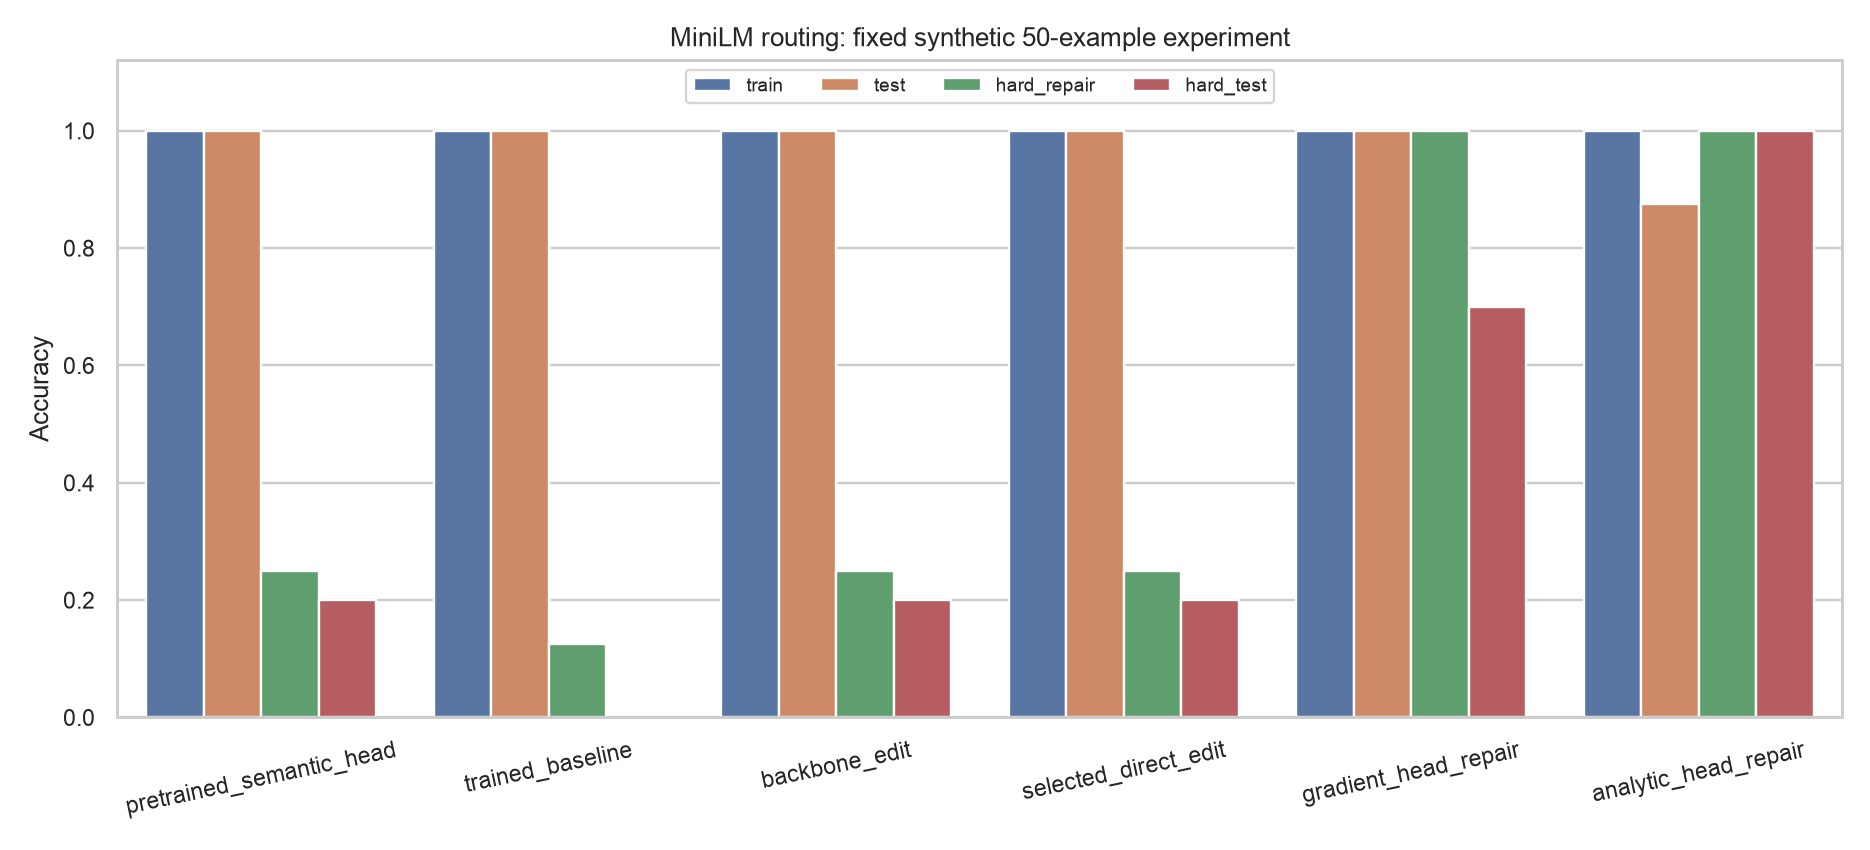

,3,7,11,15,19,23
method,pretrained_semantic_head,trained_baseline,backbone_edit,selected_direct_edit,gradient_head_repair,analytic_head_repair
split,hard_test,hard_test,hard_test,hard_test,hard_test,hard_test
n,10,10,10,10,10,10
correct,2,0,2,2,7,10
accuracy,0.2,0.0,0.2,0.2,0.7,1.0
accuracy_ci95_low,0.056682,0.0,0.056682,0.056682,0.396778,0.722467
accuracy_ci95_high,0.509838,0.277533,0.509838,0.509838,0.892209,1.0
balanced_accuracy,0.2,0.0,0.2,0.2,0.7,1.0
mcc,-0.6,-1.0,-0.654654,-0.6,0.5,1.0
roc_auc,0.04,0.0,0.2,0.12,0.84,1.0


,method,split,n,correct,accuracy,accuracy_ci95_low,accuracy_ci95_high,balanced_accuracy,mcc,roc_auc,...,f1_weighted,precision_billing,recall_billing,f1_billing,support_billing,precision_account_access,recall_account_access,f1_account_access,support_account_access,ece_10_bins
0,pretrained_semantic_head,train,24,24,1.000,0.862024,1.000000,1.000,1.000000,1.0000,...,1.000000,1.000000,1.00,1.000000,12,1.000000,1.00,1.000000,12,0.070443
1,pretrained_semantic_head,test,8,8,1.000,0.675592,1.000000,1.000,1.000000,1.0000,...,1.000000,1.000000,1.00,1.000000,4,1.000000,1.00,1.000000,4,0.072134
2,pretrained_semantic_head,hard_repair,8,2,0.250,0.071479,0.590725,0.250,-0.577350,0.0625,...,0.200000,0.333333,0.50,0.400000,4,0.000000,0.00,0.000000,4,0.466181
3,pretrained_semantic_head,hard_test,10,2,0.200,0.056682,0.509838,0.200,-0.600000,0.0400,...,0.200000,0.200000,0.20,0.200000,5,0.200000,0.20,0.200000,5,0.489761
4,trained_baseline,train,24,24,1.000,0.862024,1.000000,1.000,1.000000,1.0000,...,1.000000,1.000000,1.00,1.000000,12,1.000000,1.00,1.000000,12,0.235278
5,trained_baseline,test,8,8,1.000,0.675592,1.000000,1.000,1.000000,1.0000,...,1.000000,1.000000,1.00,1.000000,4,1.000000,1.00,1.000000,4,0.246370
6,trained_baseline,hard_repair,8,1,0.125,0.022417,0.470888,0.125,-0.774597,0.0625,...,0.111111,0.200000,0.25,0.222222,4,0.000000,0.00,0.000000,4,0.488435
7,trained_baseline,hard_test,10,0,0.000,0.000000,0.277533,0.000,-1.000000,0.0000,...,0.000000,0.000000,0.00,0.000000,5,0.000000,0.00,0.000000,5,0.619679
8,backbone_edit,train,24,24,1.000,0.862024,1.000000,1.000,1.000000,1.0000,...,1.000000,1.000000,1.00,1.000000,12,1.000000,1.00,1.000000,12,0.399931
9,backbone_edit,test,8,8,1.000,0.675592,1.000000,1.000,1.000000,1.0000,...,1.000000,1.000000,1.00,1.000000,4,1.000000,1.00,1.000000,4,0.406629


,method,fixed,broken,both_correct,both_wrong,exact_mcnemar_p
0,backbone_edit,2,0,0,8,0.500000
1,selected_direct_edit,2,0,0,8,0.500000
2,gradient_head_repair,7,0,0,3,0.015625
3,analytic_head_repair,10,0,0,0,0.001953


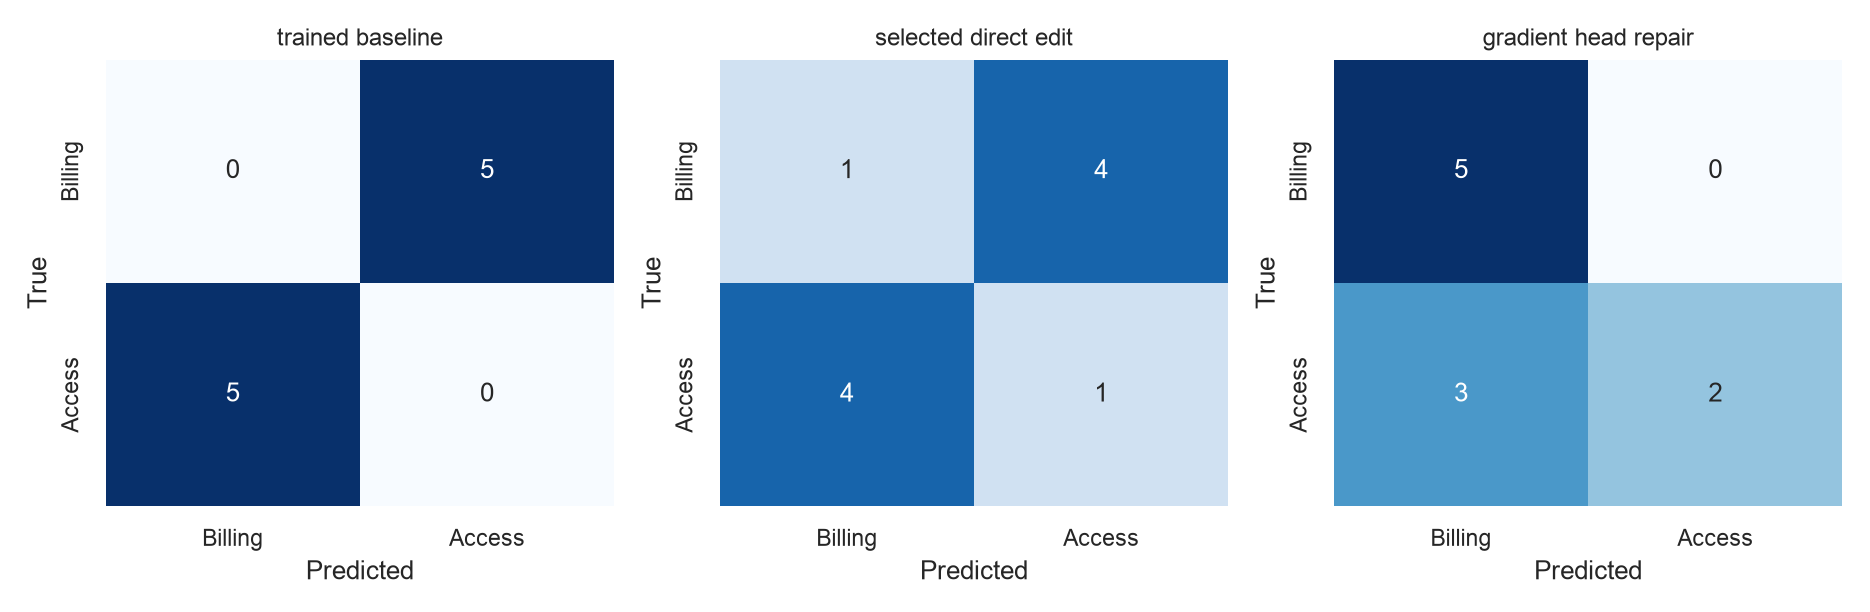

In [12]:
metrics = pd.read_csv(ROOT / 'results/metrics.csv')
display(metrics.pivot(index='method', columns='split', values='accuracy').style.format('{:.0%}'))
display(Image(filename=str(ROOT / 'results/accuracy_comparison.png')))
display(metrics[metrics['split']=='hard_test'].T)
display(metrics)
display(pd.read_csv(ROOT / 'results/paired_hard_test.csv'))
display(Image(filename=str(ROOT / 'results/hard_test_confusions.png')))

## 6. Every held-out prediction and remaining failures

All examples are retained, including regressions. No post-evaluation candidate changes are made.

In [13]:
predictions = pd.read_csv(ROOT / 'results/predictions.csv')
hard = predictions[predictions['split']=='hard_test']
display(hard[['method','id','text','label_name','predicted','p_billing','p_account_access','correct']])
display(Markdown('**Remaining selected-edit errors:**'))
display(hard[(hard['method']=='selected_direct_edit') & (hard['correct']==0)])
display(Markdown((ROOT / 'RESULTS.md').read_text()))

,method,id,text,label_name,predicted,p_billing,p_account_access,correct
40,pretrained_semantic_head,hard_test_00,Archived routing metadata: Account access depa...,billing,0,0.583472,0.416528,1
41,pretrained_semantic_head,hard_test_01,Archived routing metadata: Billing department....,account_access,0,0.615885,0.384115,0
42,pretrained_semantic_head,hard_test_02,Archived routing metadata: Account access depa...,billing,1,0.409604,0.590396,0
43,pretrained_semantic_head,hard_test_03,Archived routing metadata: Billing department....,account_access,0,0.842128,0.157872,0
44,pretrained_semantic_head,hard_test_04,Archived routing metadata: Account access depa...,billing,1,0.323940,0.676060,0
45,pretrained_semantic_head,hard_test_05,Archived routing metadata: Billing department....,account_access,0,0.914275,0.085725,0
46,pretrained_semantic_head,hard_test_06,Archived routing metadata: Account access depa...,billing,1,0.445840,0.554160,0
47,pretrained_semantic_head,hard_test_07,Archived routing metadata: Billing department....,account_access,0,0.911338,0.088662,0
48,pretrained_semantic_head,hard_test_08,Archived routing metadata: Account access depa...,billing,1,0.314079,0.685921,0
49,pretrained_semantic_head,hard_test_09,Archived routing metadata: Billing department....,account_access,1,0.476029,0.523971,1


**Remaining selected-edit errors:**

,method,id,split,label,label_name,legacy_route,request,text,predicted,p_billing,p_account_access,correct
191,selected_direct_edit,hard_test_01,hard_test,1,account_access,0,There is no payment problem anymore. I need a ...,Archived routing metadata: Billing department....,0,0.534762,0.465238,0
192,selected_direct_edit,hard_test_02,hard_test,0,billing,1,Authentication succeeds. What remains is an in...,Archived routing metadata: Account access depa...,1,0.424919,0.575081,0
193,selected_direct_edit,hard_test_03,hard_test,1,account_access,0,The renewal amount is correct. What remains is...,Archived routing metadata: Billing department....,0,0.869036,0.130964,0
194,selected_direct_edit,hard_test_04,hard_test,0,billing,1,Keep my credentials unchanged; please return t...,Archived routing metadata: Account access depa...,1,0.339873,0.660127,0
195,selected_direct_edit,hard_test_05,hard_test,1,account_access,0,Keep my payment method unchanged; please repla...,Archived routing metadata: Billing department....,0,0.911793,0.088207,0
196,selected_direct_edit,hard_test_06,hard_test,0,billing,1,The verification screen is fine. Remove the un...,Archived routing metadata: Account access depa...,1,0.490990,0.509009,0
197,selected_direct_edit,hard_test_07,hard_test,1,account_access,0,The fee on my bill is fine. Help me get throug...,Archived routing metadata: Billing department....,0,0.917970,0.082030,0
198,selected_direct_edit,hard_test_08,hard_test,0,billing,1,I can enter my profile normally. The next paym...,Archived routing metadata: Account access depa...,1,0.321110,0.678890,0


# MiniLM direct weight editing: measured results

This is a small, synthetic shortcut-learning experiment inspired by weight-space programming, not a reproduction of the paper.

Device: mps; seed 42; training 2.6s; edit stage 0.5s.
Selected candidate: `semantic_head_0.5`; changed 770/22,713,986 scalar parameters.

Accuracy (correct / total):

| Method | Train (24) | Test (8) | Hard repair (8) | Hard test (10) |
|---|---:|---:|---:|---:|
| pretrained_semantic_head | 24/24 (100.0%) | 8/8 (100.0%) | 2/8 (25.0%) | 2/10 (20.0%) |
| trained_baseline | 24/24 (100.0%) | 8/8 (100.0%) | 1/8 (12.5%) | 0/10 (0.0%) |
| backbone_edit | 24/24 (100.0%) | 8/8 (100.0%) | 2/8 (25.0%) | 2/10 (20.0%) |
| selected_direct_edit | 24/24 (100.0%) | 8/8 (100.0%) | 2/8 (25.0%) | 2/10 (20.0%) |
| gradient_head_repair | 24/24 (100.0%) | 8/8 (100.0%) | 8/8 (100.0%) | 7/10 (70.0%) |
| analytic_head_repair | 24/24 (100.0%) | 7/8 (87.5%) | 8/8 (100.0%) | 10/10 (100.0%) |

Hard-test accuracy changed from 0% to 20%.
Backbone-only candidate selected: `backbone_projection_1.0`. A no-op means neither tested backbone intervention met the selection rule with a better outcome.

The main edit is chosen on repair examples, never on hard-test examples. A semantic head rewrite uses extra authored class probes; it is a head replacement, and does not establish that MiniLM learned negation. The ordinary test shares the training shortcut. Both hard splits reverse it. Check per-example predictions for unresolved failures.

The analytic head control is supervised ridge fitting from repair labels, despite requiring no gradients. It is not equivalent to the paper’s reasoning-only intervention. Its target margin is 3 and ridge parameter is 0.01, fixed before final evaluation.

All classification and probability metrics, Wilson accuracy intervals, paired exact McNemar comparisons, candidate scores and tensor-change counts are in results/. With only ten hard-test examples, a single example changes accuracy by ten percentage points. Single seed, synthetic data, and shared hard-case construction patterns limit generalization claims.

References:
- https://rikiyat.github.io/blog/weight-space-programming/
- https://github.com/RikiyaT/lm_understand-logs/tree/main/exp8_math
- https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2


## 7. Saved artifacts and exact tensor replay

`checkpoints/baseline.pt` stores all baseline weights. `edited_tensors.pt` stores exact replacement tensors; `weight_patch.pt` stores additive diffs and the selected candidate. Prefer exact replacements when reproducing predictions because floating-point subtraction/addition need not round-trip bitwise. `predict_ticket.py` loads these locally without retraining. `results/` contains every metric, prediction, candidate and measured runtime.

Sources: [paper](https://rikiyat.github.io/blog/weight-space-programming/), [released Experiment 8 protocol](https://github.com/RikiyaT/lm_understand-logs/tree/main/exp8_math), [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).

In [14]:
display(pd.DataFrame([{'file':str(p.relative_to(ROOT)), 'bytes':p.stat().st_size} for folder in ['data','results','checkpoints'] for p in sorted((ROOT/folder).rglob('*')) if p.is_file()]))

,file,bytes
0,data/SHA256.txt,79
1,data/tickets.json,19658
2,results/accuracy_comparison.png,60382
3,results/confusion_matrices.json,2392
4,results/diagnostic_probes.json,838
5,results/edit_candidates.csv,307
6,results/hard_test_confusions.png,46609
7,results/method_weight_changes.csv,348
8,results/metrics.csv,5691
9,results/paired_hard_test.csv,199
